# code_137 · Rollout error and independently verified inverse design

**Book:** section 26.5. A self-contained operator-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_26_GUIDE.md), [run evidence](../CHAPTER_26_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_137).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3137;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3137


<a id="rollout-and-design-contract"></a>
 ## Two small tasks separate surrogate reuse from physical verification
 First fit a16-point periodic heat-step Ridge map on128 source functions, with a declared source-label offset0.002 and independent Gaussian noise SD0.003. Thirty-two clean development functions choose alpha1e-5/0.001/0.1; sixty-four clean final initial functions assess one and forty repeated steps. Compare frozen raw rollout with a projection preserving each initial field's known mean. Second, fit a scalar steady-bar center-displacement surrogate from64 source design cases in[−0.6,0.6]², select alpha on16 development cases and assess32 independent cases with a refined native solver. Optimize for requested displacement0.22 over wider declared design bounds[−1.5,1.5]², then verify the proposal independently. A solver-assisted refinement is separate and counted; bootstrap spread is not a calibrated uncertainty interval. Neither task imports the other chapter notebooks.


,step,raw_MSE,projected_MSE,raw_mean_absolute_error,projected_mean_absolute_error
0,1,0.000004,7.748861e-07,0.001918,4.846384e-17
4,5,0.000099,5.245270e-06,0.009647,3.209238e-17
9,10,0.000390,1.216003e-05,0.019379,2.688821e-17
19,20,0.001556,2.561068e-05,0.039004,2.406929e-17
39,40,0.006285,5.157989e-05,0.078728,1.550409e-17


Design verification: {'heat_selected_alpha': 0.001, 'heat_source_label_offset': 0.002, 'heat_source_noise_sd': 0.003, 'heat_case_counts': [128, 32, 64], 'fitted_one_step_spectral_radius': 1.0006207976582284, 'design_case_counts': [64, 16, 32], 'design_selected_alpha': 0.1, 'final_design_surrogate_MSE': 1.9741894514636468e-08, 'surrogate_gradient_max_difference': 1.1088630014199907e-12, 'requested_displacement': 0.22, 'proposal': [-0.0016995093465610074, 0.9419100045018169], 'proposal_surrogate_prediction': 0.21990630840029393, 'proposal_independent_solver': 0.22043659982336453, 'proposal_accepted_at_tolerance': True, 'verification_tolerance': 0.0005, 'bootstrap_predictions': [0.2202959470071097, 0.21995810373277505, 0.21991041132749878, 0.21967009998082093], 'bootstrap_standard_deviation': 0.000257783922530656, 'refined_design': [9.501608443145284e-07, 0.9366530528569532], 'refined_independent_solver': 0.21990396860850736, 'surrogate_optimization_calls': 9, 'native_solver_call_counts':

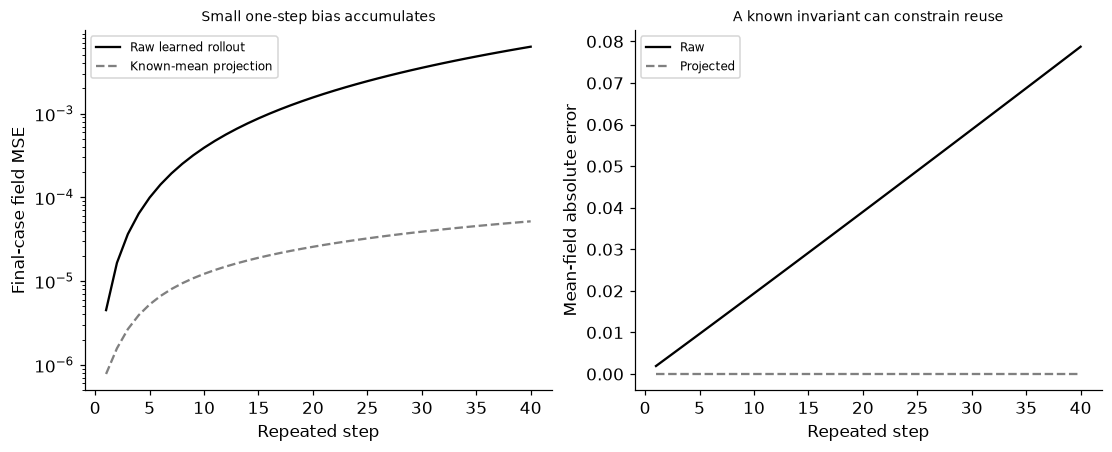

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import Ridge
from scipy.optimize import minimize
n=16;x=np.arange(n)/n;nu=.003;delta=.1;coeff=rng.normal(size=(224,9));coeff[:,0]*=.2
def heat(c,steps):
    result=np.repeat(c[:,:1],n,axis=1)
    for k in range(1,5):result+=np.exp(-nu*(2*np.pi*k)**2*delta*steps)*(c[:,2*k-1,None]*np.cos(2*np.pi*k*x)+c[:,2*k,None]*np.sin(2*np.pi*k*x))
    return result
train_input=heat(coeff[:128],0);train_label=heat(coeff[:128],1)+.002+rng.normal(0,.003,(128,n));dev_input=heat(coeff[128:160],0);dev_truth=heat(coeff[128:160],1);choices=[]
for alpha in [1e-5,.001,.1]:
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha));model.fit(train_input,train_label);score=float(np.mean((model.predict(dev_input)-dev_truth)**2));choices.append((score,alpha,model))
_,heat_alpha,heat_model=min(choices,key=lambda a:a[0]);initial=heat(coeff[160:],0);raw=initial.copy();projected=initial.copy();initial_mean=initial.mean(1,keepdims=True);rollout=[]
for step in range(1,41):
    raw=heat_model.predict(raw);projected=heat_model.predict(projected);projected+=initial_mean-projected.mean(1,keepdims=True);truth=heat(coeff[160:],step);rollout.append({'step':step,'raw_MSE':float(np.mean((raw-truth)**2)),'projected_MSE':float(np.mean((projected-truth)**2)),'raw_mean_absolute_error':float(np.mean(np.abs(raw.mean(1)-initial_mean[:,0]))),'projected_mean_absolute_error':float(np.mean(np.abs(projected.mean(1)-initial_mean[:,0])))})
np.testing.assert_allclose(projected.mean(1),initial_mean[:,0],atol=1e-14,rtol=0);linear=heat_model[-1].coef_/heat_model[0].scale_[None,:];spectral_radius=float(np.max(np.abs(np.linalg.eigvals(linear))))
counters={};designs=rng.uniform(-.6,.6,(112,2))
def native_bar(z,nodes):
    counters[nodes]=counters.get(nodes,0)+1;a,b=z;h=1/(nodes+1);xx=np.arange(1,nodes+1)*h;edge=(np.arange(nodes+1)+.5)*h;k=np.exp(.4*a*np.sin(2*np.pi*edge));forcing=1+b*np.sin(np.pi*xx);K=np.diag((k[:-1]+k[1:])/h**2)+np.diag(-k[1:-1]/h**2,1)+np.diag(-k[1:-1]/h**2,-1);u=np.linalg.solve(K,forcing);return float(u[nodes//2])
labels=np.array([native_bar(z,63) for z in designs[:80]]);final_truth=np.array([native_bar(z,127) for z in designs[80:]]);models=[]
for alpha in [1e-5,.001,.1]:
    fit=make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=alpha));fit.fit(designs[:64],labels[:64]);score=float(np.mean((fit.predict(designs[64:80])-labels[64:80])**2));models.append((score,alpha,fit))
_,design_alpha,design_model=min(models,key=lambda a:a[0]);coef=design_model[-1].coef_/design_model[1].scale_;intercept=float(design_model[-1].intercept_-coef@design_model[1].mean_)
def surrogate(z):
    a,b=z;features=np.array([a,b,a*a,a*b,b*b]);jac=np.array([[1,0],[0,1],[2*a,0],[b,a],[0,2*b]]);return float(intercept+features@coef),jac.T@coef
z=np.array([.1,-.2]);value,gradient=surrogate(z);eps=1e-6;finite=np.array([(surrogate(z+eps*np.eye(2)[j])[0]-surrogate(z-eps*np.eye(2)[j])[0])/(2*eps) for j in range(2)]);np.testing.assert_allclose(gradient,finite,atol=1e-10,rtol=1e-8)
target=.22;regularizer=1e-5;surrogate_calls=[0]
def objective(z):
    surrogate_calls[0]+=1;p,g=surrogate(z);return (p-target)**2+regularizer*(z@z),2*(p-target)*g+2*regularizer*z
proposal=minimize(objective,np.zeros(2),jac=True,bounds=[(-1.5,1.5)]*2,method='L-BFGS-B',options={'ftol':1e-14,'gtol':1e-10});assert proposal.success
proposed=proposal.x;predicted=surrogate(proposed)[0];verified=native_bar(proposed,257);bootstrap=[]
for j in range(4):
    indices=rng.choice(64,64,replace=True);fit=make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=design_alpha));fit.fit(designs[indices],labels[indices]);bootstrap.append(float(fit.predict(proposed[None,:])[0]))
acceptance_tolerance=.0005;accepted=abs(verified-target)<=acceptance_tolerance
# A trusted-solver refinement is explicitly a new, more expensive optimization stage.
def solver_objective(z):return (native_bar(z,127)-target)**2+regularizer*(z@z)
refined=minimize(solver_objective,proposed,bounds=[(-1.5,1.5)]*2,method='L-BFGS-B',options={'ftol':1e-14,'gtol':1e-9});assert refined.success;refined_verified=native_bar(refined.x,257)
RESULTS.update(rollout=rollout,heat_selected_alpha=heat_alpha,heat_source_label_offset=.002,heat_source_noise_sd=.003,heat_case_counts=[128,32,64],fitted_one_step_spectral_radius=spectral_radius,design_case_counts=[64,16,32],design_selected_alpha=design_alpha,final_design_surrogate_MSE=float(np.mean((design_model.predict(designs[80:])-final_truth)**2)),surrogate_gradient_max_difference=float(np.max(np.abs(gradient-finite))),requested_displacement=target,proposal=proposed.tolist(),proposal_surrogate_prediction=predicted,proposal_independent_solver=verified,proposal_accepted_at_tolerance=bool(accepted),verification_tolerance=acceptance_tolerance,bootstrap_predictions=bootstrap,bootstrap_standard_deviation=float(np.std(bootstrap,ddof=1)),refined_design=refined.x.tolist(),refined_independent_solver=refined_verified,surrogate_optimization_calls=surrogate_calls[0],native_solver_call_counts={str(k):v for k,v in counters.items()});display(pd.DataFrame(rollout).iloc[[0,4,9,19,39]]);print('Design verification:',{k:v for k,v in RESULTS.items() if k!='rollout'})
fig,axes=plt.subplots(1,2,figsize=(10,4));steps=[r['step'] for r in rollout];axes[0].semilogy(steps,[r['raw_MSE'] for r in rollout],'k-',label='Raw learned rollout');axes[0].semilogy(steps,[r['projected_MSE'] for r in rollout],'--',color='.5',label='Known-mean projection');axes[0].set(xlabel='Repeated step',ylabel='Final-case field MSE',title='Small one-step bias accumulates');axes[0].legend(fontsize=8);axes[1].plot(steps,[r['raw_mean_absolute_error'] for r in rollout],'k-',label='Raw');axes[1].plot(steps,[r['projected_mean_absolute_error'] for r in rollout],'--',color='.5',label='Projected');axes[1].set(xlabel='Repeated step',ylabel='Mean-field absolute error',title='A known invariant can constrain reuse');axes[1].legend(fontsize=8);plt.show()


<a id="verification-and-amortization"></a>
 ## Optimize the surrogate, then ask the physical solver a new question
 The proposed design may lie beyond source parameter support even though the optimizer respects its broader design bounds. An analytic polynomial gradient is checked independently before use. A257-interior-position native solver verifies its requested displacement. Solver-assisted refinement uses127 positions and is separately reverified at257; its extra calls are counted rather than hidden inside a claim of cheap inference. Four bootstrap fits quantify only this finite fit procedure's variability; agreement does not validate extrapolation or calibrate a predictive interval. The heat experiment has its own biased/noisy label provenance and exact final reference, separate from steady design. Break-even use must account for data generation, training, serving and physical verification. No measured industrial runtime speedup is inferred from the solve counts.


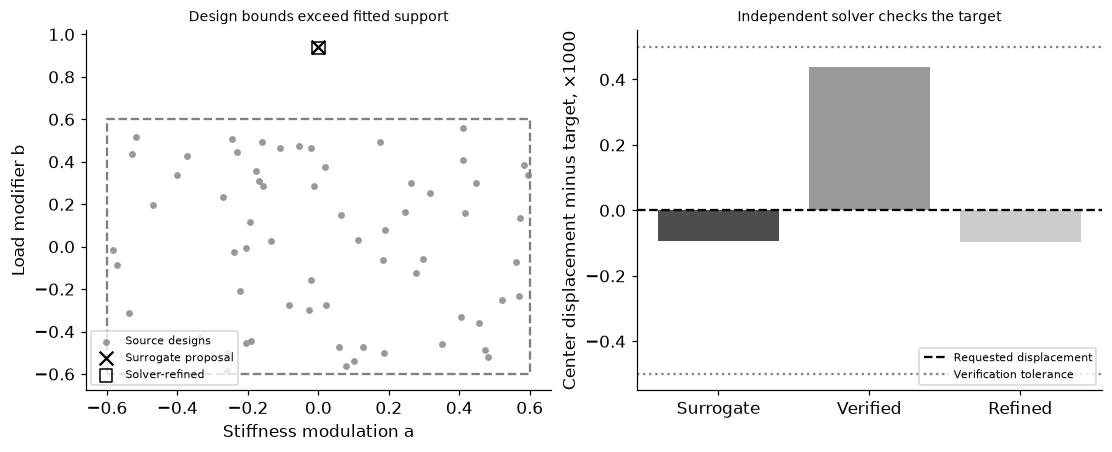

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(designs[:64,0],designs[:64,1],s=12,color='.6',label='Source designs');axes[0].scatter(*proposed,marker='x',s=80,color='black',label='Surrogate proposal');axes[0].scatter(*refined.x,marker='s',facecolors='none',edgecolors='black',s=65,label='Solver-refined');axes[0].plot([-.6,.6,.6,-.6,-.6],[-.6,-.6,.6,.6,-.6],'--',color='.5');axes[0].set(xlabel='Stiffness modulation a',ylabel='Load modifier b',title='Design bounds exceed fitted support');axes[0].legend(fontsize=7,loc='lower left');axes[1].bar(range(3),1000*(np.array([predicted,verified,refined_verified])-target),color=['.3','.6','.8']);axes[1].axhline(0,color='black',linestyle='--',label='Requested displacement');axes[1].axhline(1000*acceptance_tolerance,color='.5',linestyle=':');axes[1].axhline(-1000*acceptance_tolerance,color='.5',linestyle=':',label='Verification tolerance');axes[1].set(xticks=range(3),xticklabels=['Surrogate','Verified','Refined'],ylabel='Center displacement minus target, ×1000',title='Independent solver checks the target');axes[1].legend(fontsize=7,loc='lower right');plt.show()
assert np.isfinite(refined_verified) and abs(refined_verified-target)<.001


In [4]:
summary={'example_id':'code_137','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual repeated learned heat-step rollout', 'mass-preserving projection audit', 'surrogate design optimization with analytic gradients', 'independent refined solver verification', 'bootstrap disagreement and actual solve counts'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual repeated learned heat-step rollout", "mass-preserving projection audit", "surrogate design optimization with analytic gradients", "independent refined solver verification", "bootstrap disagreement and actual solve counts"], "elapsed_seconds": 1.083, "example_id": "code_137", "hardware": "Darwin arm64 CPU", "results": {"bootstrap_predictions": [0.2202959470071097, 0.21995810373277505, 0.21991041132749878, 0.21967009998082093], "bootstrap_standard_deviation": 0.000257783922530656, "design_case_counts": [64, 16, 32], "design_selected_alpha": 0.1, "final_design_surrogate_MSE": 1.9741894514636468e-08, "fitted_one_step_spectral_radius": 1.0006207976582284, "heat_case_counts": [128, 32, 64], "heat_selected_alpha": 0.001, "heat_source_label_offset": 0.002, "heat_source_noise_sd": 0.003, "native_solver_call_counts": {"127": 68, "257": 2, "63": 80}, "proposal": [-0.0016995093465610074, 0.9419100045018169], "proposal_accepted_at_tolerance"